# Tasks 2 and 3: Regression

In this notebook, we show the code for the training of a regression model with multiple output channels to predict the voting fraction for different answers to questions 2, 7, 6 and 8 from the kaggle survey.

The answers to these questions depend on answers to previous questions (thus imposing a "parent" and "child" relationship), so to take this into account in our model, we have taken two approaches: a "flat" regression model that independently computes each question's answer with a hierarchical loss function that forces the sum of the voting fractions of "child" classes to be equal to their given "parent" class; and a conditional probability "tree" model that incorporates these relationships in the model's architechture, using bayesian conditional probabilities to encode the rel

In [ ]:
import torch
from torch import nn
from torch.optim import AdamW, lr_scheduler
from torch.amp import GradScaler
from pathlib import Path

from utils.data import regression_dataloaders
from utils.model import CNN
from utils.train import fit, FullHierarchicalLoss


# "flat" = Independent multi-label | "tree" = Bayesian probability structure
ARCH = 'flat'
EPOCHS = 50
BATCH_SIZE = 64
IMG_SIZE = 200
LABELS_PATH = Path('data/labels.csv')


torch.backends.cudnn.benchmark = True
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


train_loader, val_loader, test_loader = regression_dataloaders(
    labels_path=LABELS_PATH,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    architecture=ARCH
)

# Note: out_channels=17 is only strictly necessary for the 'flat' architecture.
model = CNN(
    in_channels=3,
    out_channels=17,
    input_shape=(IMG_SIZE, IMG_SIZE),
    hidden_channels=32,
    final_hidden_channels=512,
    n_blocks=5,
    architecture=ARCH
).to(device)

optimizer = AdamW(model.parameters(), lr=0.0003, weight_decay=1e-3)
scheduler = lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=1e-3,
    steps_per_epoch=len(train_loader),
    epochs=EPOCHS,
    pct_start=0.3,
    anneal_strategy='cos'
)
scaler = GradScaler('cuda')


# Flat requires the custom loss to enforce hierarchical rules after prediction.
# Tree inherently calculates valid distributions, so standard MSE is sufficient.
loss_fn = FullHierarchicalLoss(lambda_reg=0.1) if ARCH == 'flat' else nn.MSELoss()


train_losses, val_losses, _, _ = fit(
    epochs=EPOCHS,
    loss_function=loss_fn,
    model=model,
    optimizer=optimizer,
    train_loader=train_loader,
    validation_loader=val_loader,
    device=device,
    scaler=scaler,
    architecture=ARCH,
    patience=7,
    scheduler=scheduler
)

## Testing

Like in the regression case, we run the model on a given test dataset, obtaining histograms comparing the distributions of the real and predicted voting fractions, and a heatmap 2D histogram that compares real and predicted values to better visualize the model's performance, as well as the validation and training losses.

For the flat regression case, the validation loss is significantly lower than the training loss due to the weighted sampling implemented in the training dataset, artificially increasing the training loss.

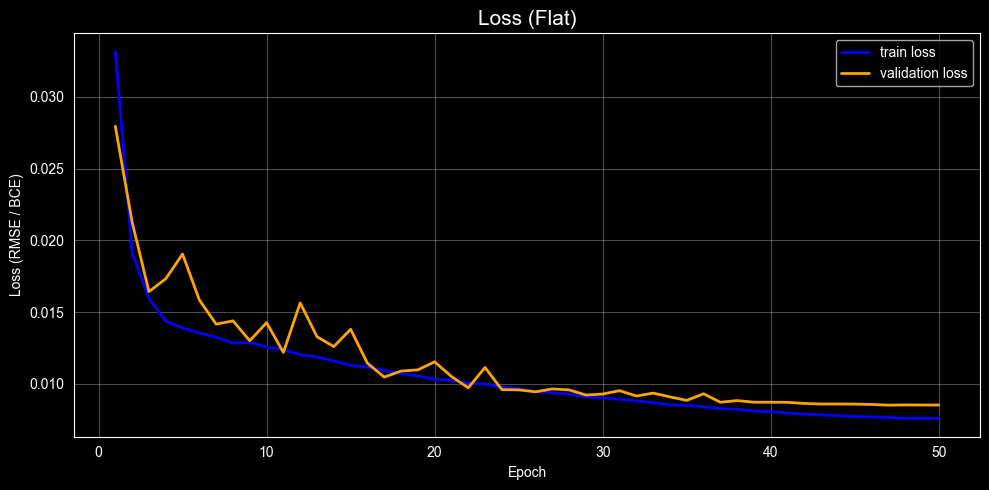

🚀 INITIATING FINAL EVALUATION PIPELINE

[Phase 1] Extracting Validation Probabilities...

[Phase 2] Skipping Threshold Optimization (Regression Model Detected)...

[Phase 3] Executing Final Test Set with TTA...

Running inference on Test Set (Architecture: flat | TTA: ON)...


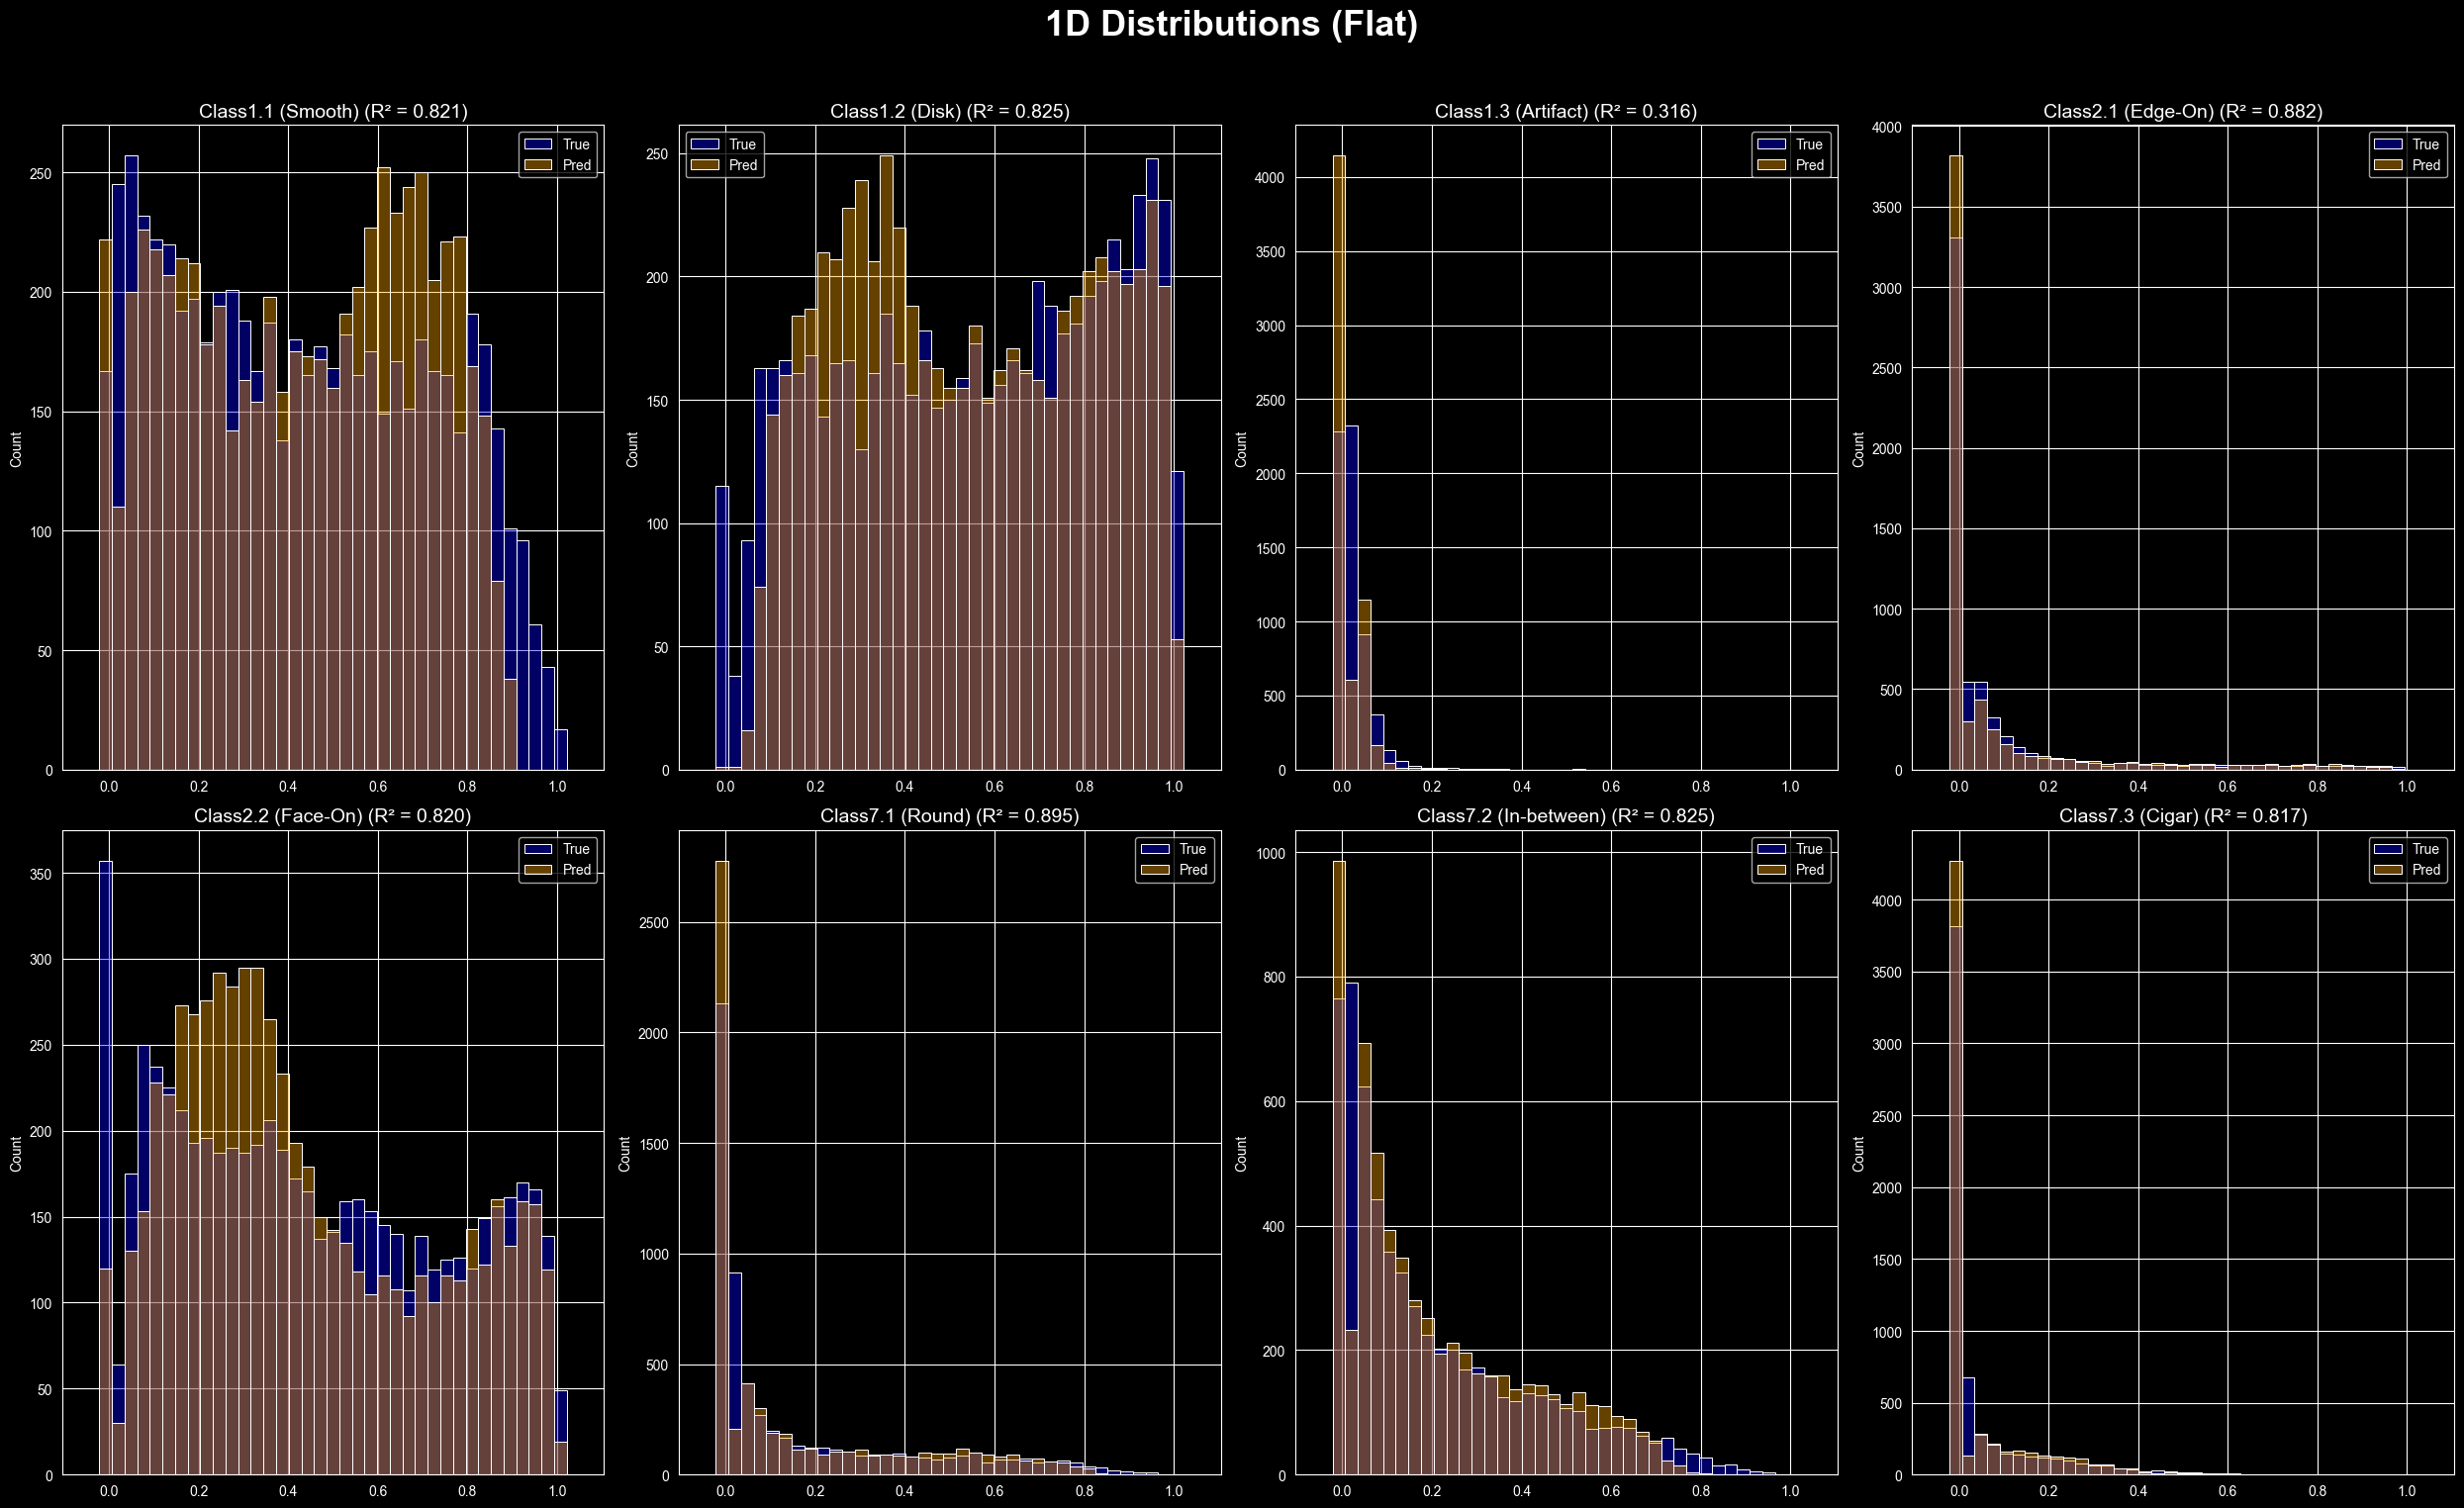

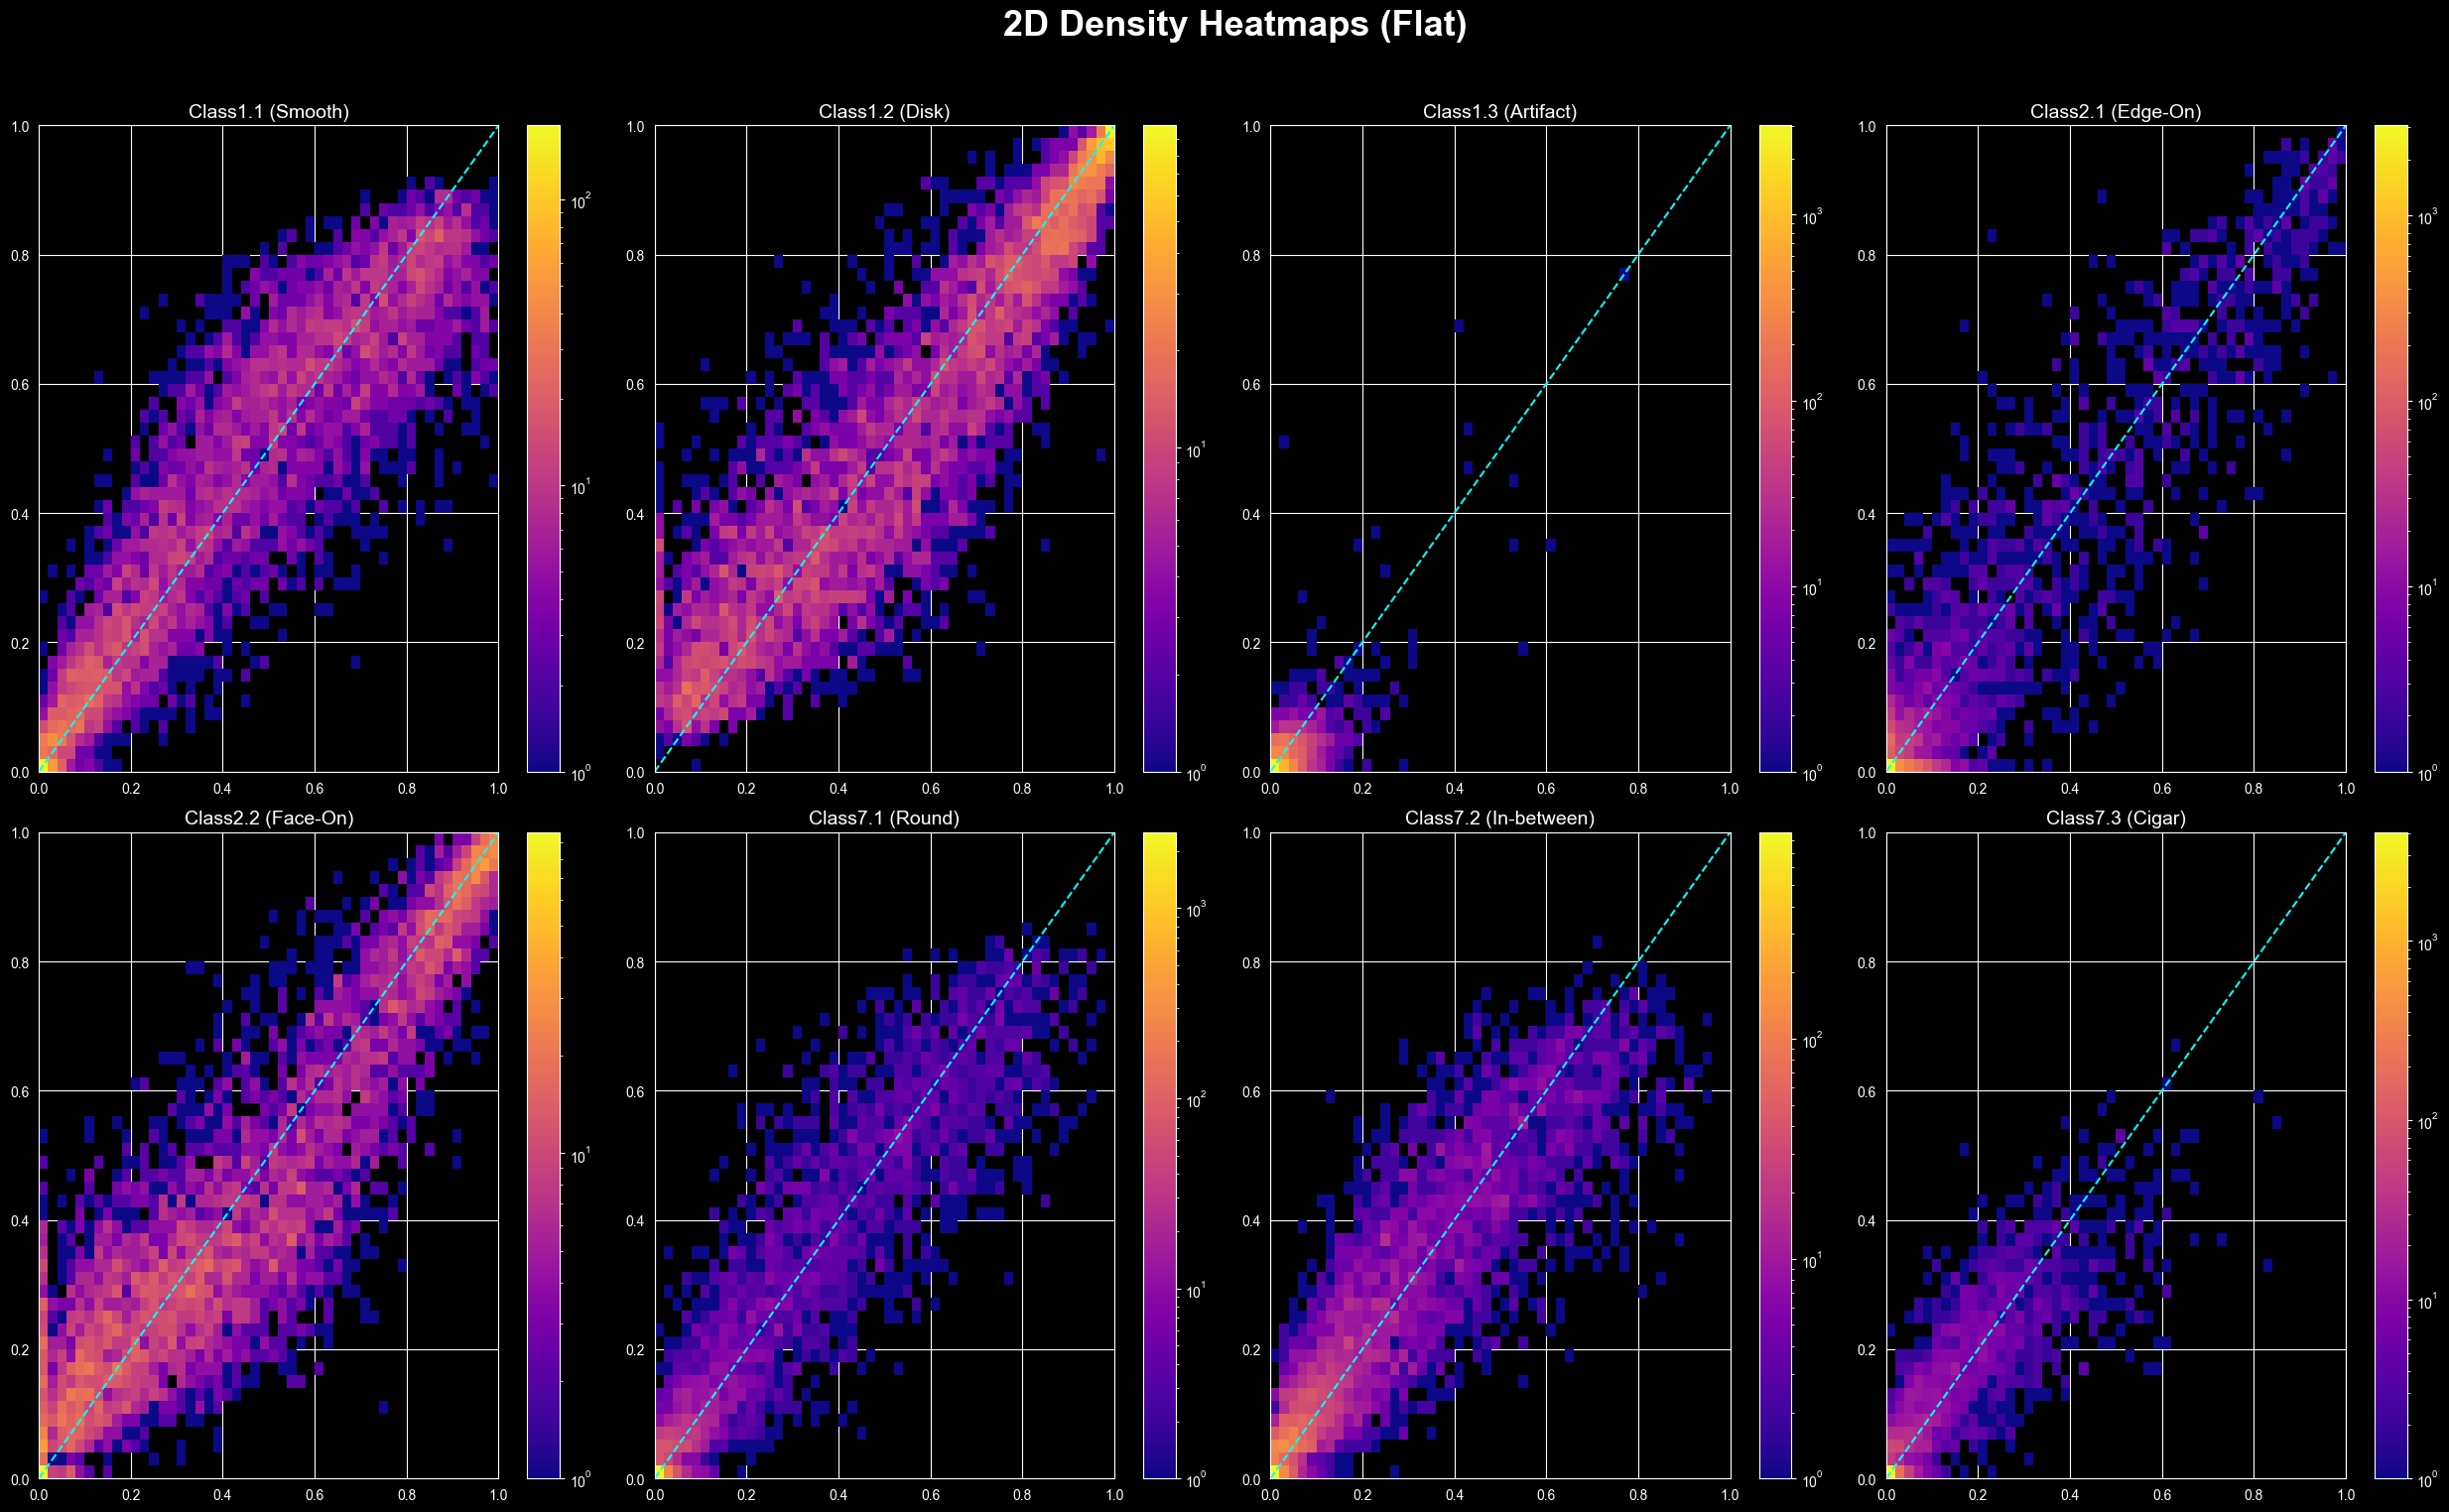

In [4]:
from utils.plotting import plot_loss, execute_final_evaluation

plot_loss(train_losses, val_losses, task=ARCH)

model.load_state_dict(torch.load('best_model.pth'))
execute_final_evaluation(model, val_loader, test_loader, device)